In [1]:
# if on mac, uncomment and run the following:

%matplotlib osx 

In [2]:
import math
import random
import numpy as np

import matplotlib.pyplot as plt
plt.rcParams['keymap.save'] = [] # so S in WASD commands work
from shapely.affinity import translate
from shapely.geometry import Point, Polygon, MultiPolygon
from shapely.prepared import prep

In [3]:
xmin, xmax = 0, 10
ymin, ymax = 0, 12

BASE_OBSTACLE_POLYGONS = [
    Polygon([[5,  1], [1,  1], [3,  4], [5, 1]]),
    Polygon([[5,  5], [7,  7], [4,  6], [5,  5]]),
    Polygon([[9,  2], [8,  7], [6,  5], [9,  2]]),
    Polygon([[1, 10], [7, 10], [4,  8], [1, 10]]),
]

OBSTACLE_MOTION = [
    {'rad': 0.2, 'w': 0.90, 'p': 0.00},
    {'rad': 0.35, 'w': 0.55, 'p': 1.10},
    {'rad': 0.2, 'w': 2, 'p': 2.00},
    {'rad': 0.3, 'w': 0.70, 'p': 2.60},
]

current_obstacle_polygons = []
obstacles = None

def update_obstacles(sim_time):
    global current_obstacle_polygons, obstacles
    moved = []
    for poly, motion in zip(BASE_OBSTACLE_POLYGONS, OBSTACLE_MOTION):
        angle = motion['w'] * sim_time + motion['p']
        dx = motion['rad'] * math.cos(angle)
        dy = motion['rad'] * math.sin(angle)
        moved.append(translate(poly, xoff=dx, yoff=dy))

    current_obstacle_polygons = moved
    obstacles = prep(MultiPolygon(current_obstacle_polygons))

update_obstacles(0.0)

xstart, ystart = 6.1, 1.1

In [4]:
class Visualization:

    def __init__(self):
        plt.ion()
        self.fig, self.ax = plt.subplots()
        self._setup_axes()

    def _setup_axes(self):
        self.ax.clear()
        self.ax.grid(True)
        self.ax.set_xlim(xmin, xmax)
        self.ax.set_ylim(ymin, ymax)
        self.ax.set_aspect('equal')
        for poly in current_obstacle_polygons:
            self.ax.plot(*poly.exterior.xy, 'k-', linewidth=2)

    def draw_particles(self, particles, **kwargs):
        xs = [p.x for p in particles]
        ys = [p.y for p in particles]
        cs = [p.weight for p in particles]
        
        self.ax.scatter(xs, ys, c=cs, s=8, alpha=0.6, cmap='viridis', **kwargs)

    def draw_point(self, x, y, **kwargs):
        if x is None or y is None:
            return
        self.ax.plot(x, y, **kwargs)

    def render(self, particles, true_x, true_y, estimate=None, step_idx=None, status=''):
        self._setup_axes()
        self.draw_particles(particles)
        if estimate is not None:
            self.draw_point(estimate[0], estimate[1], marker='x', color='red')
        self.draw_point(true_x, true_y, marker='d', color='green')

        self.ax.set_title(f't={step_idx if step_idx else 0} | {status}')
        self.ax.annotate(f'true=({true_x:.2f},{true_y:.2f})', (true_x, true_y), xytext=(6, 6), textcoords='offset points', color='green')

        if estimate is not None and estimate[0] is not None:
            self.ax.annotate(f'pred=({estimate[0]:.2f},{estimate[1]:.2f})', (estimate[0], estimate[1]), xytext=(6, -6), textcoords='offset points', color='red')

        self.fig.canvas.draw_idle()
        self.fig.canvas.flush_events()

    def show(self, block=False):
        plt.show(block=block)

### Particle Representation

each particle is a hypothetical position

$$
p_i = (x_i,\ y_i,\ w_i)
$$

post update:

$$
\sum_i w_i = 1
$$



In [5]:
MAX_LIDAR = 7.5
LIDAR_STEP = 0.05

# tuning
LIDAR_NOISE = 1
ROUGHENING = 0.1  # jitter after resampling to prevent particle collapse
RANDOM_PARTICLE_FRAC = 0.1  # inject global hypotheses to recover from bad tracks
BOT_NOISE = 0.01

In [6]:
def infreespace(x, y):
    return (xmin <= x <= xmax and ymin <= y <= ymax and obstacles.disjoint(Point(x, y)))

class Particle:
    def __init__(self, x, y, weight=1.0):
        self.x = x
        self.y = y
        self.weight = weight

    def infreespace(self):
        return infreespace(self.x, self.y)

def init_particles(num_particles):
    particles = []
    while len(particles) < num_particles:
        x = random.uniform(xmin, xmax)
        y = random.uniform(ymin, ymax)

        if infreespace(x, y):
            particles.append(Particle(x, y, weight = 1.0 / num_particles))

    return particles


def move_bot(x, y, control, dt, bot_noise=BOT_NOISE):
    vx, vy = control
    x_new = x + vx * dt + random.gauss(0, bot_noise)
    y_new = y + vy * dt + random.gauss(0, bot_noise)
    if infreespace(x_new, y_new):
        return x_new, y_new
    return x, y


def sample_motion_model(control, particle, dt=1.0):
    x_new, y_new = move_bot(particle.x, particle.y, control, dt=dt)
    return Particle(x_new, y_new, weight=1.0)

In [7]:
def raycast_distance(x, y, dx, dy, max_range, step):
    d = 0.0
    while d <= max_range:
        rx = x + dx * d  
        ry = y + dy * d  

        if not (xmin <= rx <= xmax and ymin <= ry <= ymax):
            return d

        if not obstacles.disjoint(Point(rx, ry)):
            return d

        d += step

    return max_range


dirs = [(1, 0), (0, 1), (-1, 0), (0, -1)]

def sim_lidar(loc, max_range=MAX_LIDAR, step=LIDAR_STEP, add_noise=True, noise_std=LIDAR_NOISE):
    x, y = loc

    ret = []
    for (dx, dy) in dirs:
        r = raycast_distance(x, y, dx, dy, max_range=max_range, step=step)
        if add_noise:
            r += random.gauss(0, noise_std)
            r = max(0, min(max_range, r))
        ret.append(r)

    return np.array(ret)


### Measurement Model

each particle is a hypothetical

$$
p_i = (x_i,\ y_i,\ w_i)
$$

post update:

$$
\sum_i w_i = 1
$$

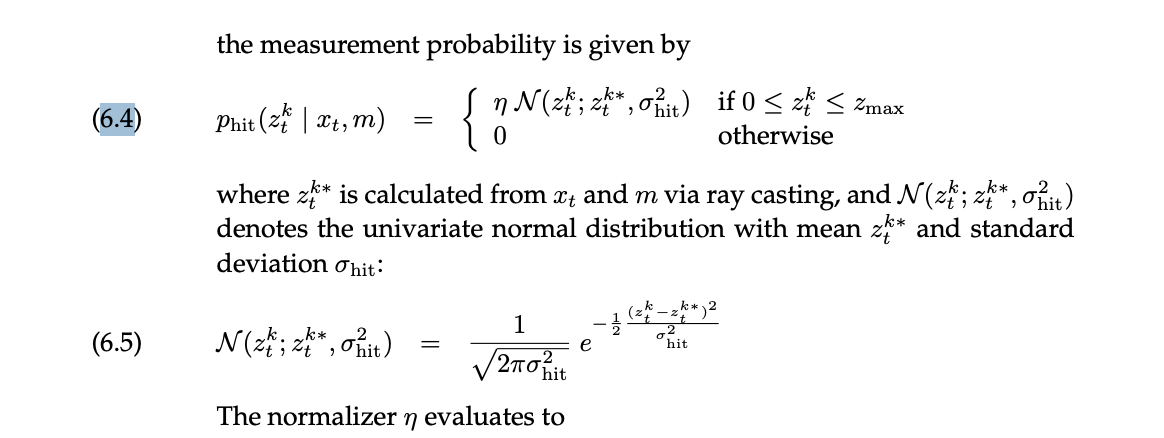

In [8]:
def measurement_model(measurement, particle, stddev=LIDAR_NOISE):
    # returns p(z | x, m)
    if not particle.infreespace():
        return 0.0
    if measurement is None:
        return 1.0

    # we are comparing the noisy scan from the "robot" to the particle's expected scan
    # noise accounted for in likelihood
    predicted = sim_lidar((particle.x, particle.y), add_noise=False)

    sigma2 = stddev * stddev

    q = 1.0
    for z, zhat in zip(measurement, predicted):
        dz = z - zhat
        nu = 1 / math.sqrt(2 * math.pi * sigma2)
        q *= nu * math.exp(-0.5 * dz**2 / sigma2)

    return q


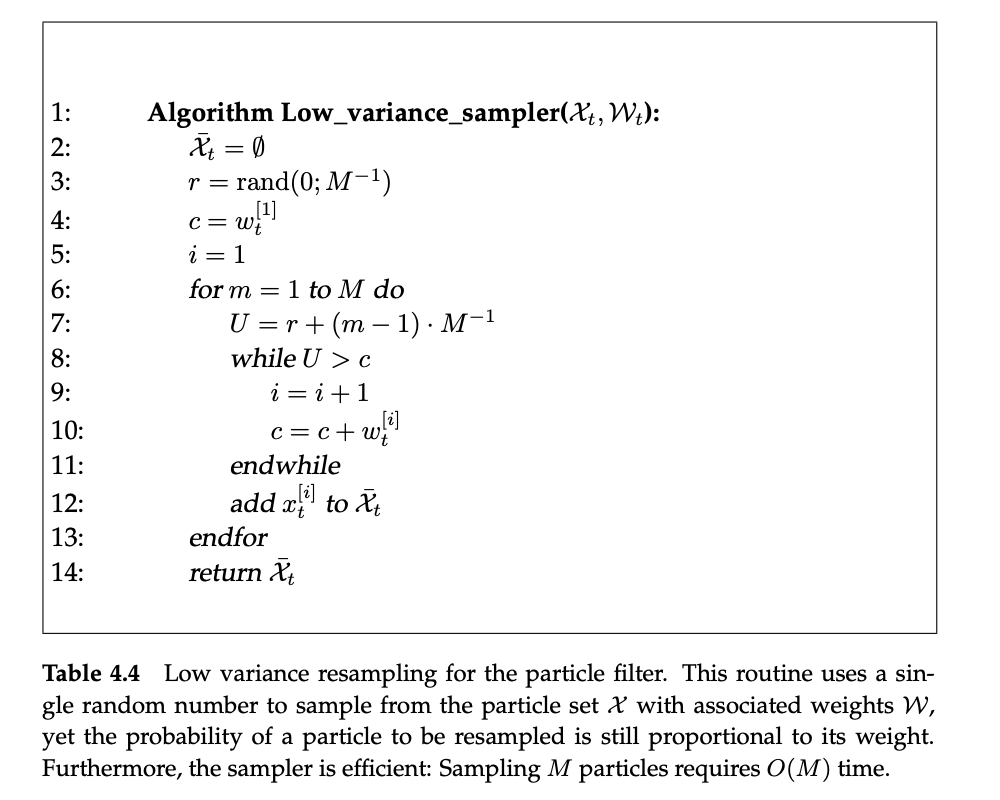

In [9]:
def low_variance_resample(particles, weights, step_idx=None):
    # draws n new particles with p proportional to weights
    n = len(particles)
    if n == 0:
        return []

    prefix = f'[t={step_idx}] ' if step_idx is not None else ''
    w_sum = sum(weights)
    if w_sum <= 0:
        print(f"{prefix}Resampled particles (ESS=0.0/{n}); all particle weights collapsed, so particles were reinitialized uniformly.")
        return init_particles(n)

    weights = [w / w_sum for w in weights]
    # expected sampling size / how many contribute basically
    ess = 1.0 / sum(w * w for w in weights)
    max_weight = max(weights)

    r = random.random() / n
    c = weights[0]
    i = 0
    new_particles = []
    random_injections = 0

    for m in range(n):
        u = r + m / n
        while u > c and i < n - 1:
            i += 1
            c += weights[i]

        if random.random() < RANDOM_PARTICLE_FRAC:
            x = random.uniform(xmin, xmax)
            y = random.uniform(ymin, ymax)
            while not infreespace(x, y):
                x = random.uniform(xmin, xmax)
                y = random.uniform(ymin, ymax)
            random_injections += 1
            new_particles.append(Particle(x, y, weight=1.0 / n))
            continue

        src = particles[i]
        x = src.x + random.gauss(0, ROUGHENING)
        y = src.y + random.gauss(0, ROUGHENING)

        if not infreespace(x, y):
            x, y = src.x, src.y
        new_particles.append(Particle(x, y, weight=1.0 / n))

    print(f"{prefix}Resampled particles (ESS = {ess:.1f}/{n}, max weight = {max_weight:.3f}).")
    if random_injections:
        print(f"{prefix}  Recovery injection: added {random_injections} random particles.")
    return new_particles


def mcl_step(particles, control, measurement, dt=1.0, step_idx=None):
    proposal = []
    weights = []

    for p in particles:
        x_new = sample_motion_model(control, p, dt=dt)
        proposal.append(x_new)
        weights.append(measurement_model(measurement, x_new))

    return low_variance_resample(proposal, weights, step_idx=step_idx)

In [10]:
visual = Visualization()
NUM_PARTICLES = 25
particles = init_particles(NUM_PARTICLES)

true_x, true_y = xstart, ystart

dt = 0.1
imp = 0.5
TIMER_MS = 100
TELEPORT_STEP = 60

WASD_MAP = {
    'w': (0.0, imp),
    'a': (-imp, 0.0),
    's': (0.0, -imp),
    'd': (imp, 0.0),
}

In [11]:
state = {
    't': -1,
    'sim_time': 0.0,
    'particles': particles,
    'true_x': true_x,
    'true_y': true_y,
    'estimate': (xstart, ystart),
    'last_key': 'n/a',
    'running': True,
}

def render_state(status=None):
    if status is None:
        status = f"last key: {state['last_key']} | drifting obstacles | q or esc quits."
    visual.render(
        state['particles'],
        state['true_x'],
        state['true_y'],
        estimate=state['estimate'],
        step_idx=state['t'] if state['t'] >= 0 else None,
        status=status,
    )

def advance_step(key):
    state['t'] += 1
    t = state['t']
    state['last_key'] = key.lower()

    control = WASD_MAP.get(key.lower(), (0.0, 0.0))

    state['true_x'], state['true_y'] = move_bot(state['true_x'], state['true_y'], control, dt=dt)

    # Simulate kidnapped robot after enough keypress-driven filter updates.
    if t == TELEPORT_STEP:
        state['true_x'] = random.uniform(xmin, xmax)
        state['true_y'] = random.uniform(ymin, ymax)
        while not infreespace(state['true_x'], state['true_y']):
            state['true_x'] = random.uniform(xmin, xmax)
            state['true_y'] = random.uniform(ymin, ymax)

    measurement = sim_lidar((state['true_x'], state['true_y']), add_noise=True)
    state['particles'] = mcl_step(state['particles'], control, measurement, dt=dt, step_idx=t)

    N = len(state['particles'])
    if N:
        state['estimate'] = (
            sum(p.x for p in state['particles']) / N,
            sum(p.y for p in state['particles']) / N,
        )
    else:
        state['estimate'] = (None, None)

    render_state()

def on_timer():
    if not state['running']:
        timer.stop()
        return
    state['sim_time'] += dt
    update_obstacles(state['sim_time'])
    render_state()

def on_key_press(event):
    key = (event.key or '').lower()
    if key in WASD_MAP:
        advance_step(key)
    elif key in ('q', 'escape'):
        state['running'] = False
        timer.stop()
        plt.close(visual.fig)

def on_close(event):
    state['running'] = False
    timer.stop()

timer = visual.fig.canvas.new_timer(interval=TIMER_MS)
timer.add_callback(on_timer)

visual.fig.canvas.mpl_connect('key_press_event', on_key_press)
visual.fig.canvas.mpl_connect('close_event', on_close)

timer.start()
visual.show(block=True)


[t=0] Resampled particles (ESS = 3.0/25, max weight = 0.353).
[t=0]   Recovery injection: added 1 random particles.
[t=1] Resampled particles (ESS = 18.2/25, max weight = 0.097).
[t=1]   Recovery injection: added 2 random particles.
[t=2] Resampled particles (ESS = 13.6/25, max weight = 0.111).
[t=2]   Recovery injection: added 3 random particles.
[t=3] Resampled particles (ESS = 13.6/25, max weight = 0.148).
[t=3]   Recovery injection: added 3 random particles.
[t=4] Resampled particles (ESS = 19.1/25, max weight = 0.073).
[t=4]   Recovery injection: added 2 random particles.
[t=5] Resampled particles (ESS = 21.0/25, max weight = 0.063).
[t=5]   Recovery injection: added 3 random particles.
[t=6] Resampled particles (ESS = 19.3/25, max weight = 0.077).
[t=6]   Recovery injection: added 3 random particles.
[t=7] Resampled particles (ESS = 20.4/25, max weight = 0.059).
[t=7]   Recovery injection: added 2 random particles.
[t=8] Resampled particles (ESS = 21.8/25, max weight = 0.055).
[t

## Reconstructed batch experiments

The original interactive MCL implementation above is preserved unchanged.  
The cells below reconstruct the experiment/analysis layer described in the final report:

1. particle-count sweep: \(N=\{10,25,50,100,200,500\}\)
2. lidar-likelihood noise sweep: \(\sigma=\{0.5,1,2,3\}\)
3. roughening sweep: \(\epsilon=\{0,0.05,0.1,0.2\}\), including ESS
4. low-variance vs. multinomial resampling
5. kidnapped-robot recovery with and without 10% random-particle injection

Each batch run uses 120 MCL updates and teleports the true robot at step 60. The experiment code saves the figures and CSV summaries under `mcl_experiment_results/`.

Because the original experiment driver was lost after I lost my Caltech email, the fixed control sequence below is a reconstruction. The analysis structure, metrics, parameter grids, trial count, and plots match the report, but rerunning this notebook is not expected to reproduce the report's exact random numerical values unless the original random seeds/control sequence are recovered.

In [ ]:
from dataclasses import dataclass
from pathlib import Path
import csv
import time

EXPERIMENT_DIR = Path("mcl_experiment_results")
FIGURE_DIR = EXPERIMENT_DIR / "figures"
EXPERIMENT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

EXPERIMENT_STEPS = 120
EXPERIMENT_TELEPORT_STEP = 60
DEFAULT_TRIALS = 5

# The report says a fixed control sequence was used, but that sequence was not
# present in the surviving notebook. This deterministic path keeps the robot
# moving through several parts of the map and is reused for every experiment.
def make_fixed_control_sequence(n_steps=EXPERIMENT_STEPS, speed=0.5):
    segments = [
        ((0.0,  speed), 20),
        (( speed, 0.0), 20),
        ((0.0, -speed), 20),
        ((-speed, 0.0), 20),
        ((0.0,  speed), 20),
        (( speed, 0.0), 20),
    ]
    controls = []
    for control, count in segments:
        controls.extend([control] * count)
    if len(controls) < n_steps:
        controls.extend([(0.0, 0.0)] * (n_steps - len(controls)))
    return controls[:n_steps]

FIXED_CONTROLS = make_fixed_control_sequence()

In [ ]:
@dataclass
class ExperimentConfig:
    num_particles: int = 100
    likelihood_sigma: float = 1.0
    true_lidar_sigma: float = 1.0
    roughening: float = 0.1
    random_particle_frac: float = 0.1
    bot_noise: float = 0.01
    resampler: str = "low_variance"   # or "multinomial"
    steps: int = EXPERIMENT_STEPS
    teleport_step: int = EXPERIMENT_TELEPORT_STEP
    dt: float = 0.1

def _random_free_particle(n, rng):
    while True:
        x = rng.uniform(xmin, xmax)
        y = rng.uniform(ymin, ymax)
        if infreespace(x, y):
            return Particle(x, y, weight=1.0 / n)

def _init_particles_rng(n, rng):
    return [_random_free_particle(n, rng) for _ in range(n)]

def _move_xy_rng(x, y, control, dt, noise_std, rng):
    vx, vy = control
    xn = x + vx * dt + rng.gauss(0, noise_std)
    yn = y + vy * dt + rng.gauss(0, noise_std)
    return (xn, yn) if infreespace(xn, yn) else (x, y)

def _sim_lidar_rng(loc, rng, noise_std=1.0, add_noise=True):
    x, y = loc
    scan = []
    for dx, dy in dirs:
        r = raycast_distance(x, y, dx, dy, max_range=MAX_LIDAR, step=LIDAR_STEP)
        if add_noise:
            r += rng.gauss(0, noise_std)
            r = max(0.0, min(MAX_LIDAR, r))
        scan.append(r)
    return np.asarray(scan)

def _measurement_likelihood(measurement, particle, sigma):
    if not particle.infreespace():
        return 0.0
    predicted = sim_lidar((particle.x, particle.y), add_noise=False)
    # Log-domain form avoids severe underflow when sigma is small.
    residual = np.asarray(measurement) - predicted
    logp = -0.5 * np.sum((residual / sigma) ** 2)
    return float(np.exp(logp))

def _normalize_weights(weights):
    w = np.asarray(weights, dtype=float)
    total = w.sum()
    if not np.isfinite(total) or total <= 0:
        return None
    return w / total

def _ess(normalized_weights):
    return float(1.0 / np.sum(np.square(normalized_weights)))

In [ ]:
def _resample_experiment(particles, weights, cfg, rng):
    n = len(particles)
    wn = _normalize_weights(weights)
    if wn is None:
        return _init_particles_rng(n, rng), 0.0

    ess = _ess(wn)

    if cfg.resampler == "low_variance":
        r = rng.random() / n
        positions = r + np.arange(n) / n
        cumulative = np.cumsum(wn)
        selected = []
        i = 0
        for u in positions:
            while i < n - 1 and u > cumulative[i]:
                i += 1
            selected.append(i)
    elif cfg.resampler == "multinomial":
        selected = rng.choices(range(n), weights=wn.tolist(), k=n)
    else:
        raise ValueError(f"unknown resampler: {cfg.resampler}")

    out = []
    for idx in selected:
        if rng.random() < cfg.random_particle_frac:
            out.append(_random_free_particle(n, rng))
            continue

        src = particles[idx]
        x = src.x + rng.gauss(0, cfg.roughening)
        y = src.y + rng.gauss(0, cfg.roughening)
        if not infreespace(x, y):
            x, y = src.x, src.y
        out.append(Particle(x, y, weight=1.0 / n))

    return out, ess

def run_experiment(cfg, seed=0, controls=FIXED_CONTROLS):
    rng = random.Random(seed)

    # Reset the dynamic map and initialize the robot/filter identically across runs.
    update_obstacles(0.0)
    true_x, true_y = xstart, ystart
    particles = _init_particles_rng(cfg.num_particles, rng)

    rows = []
    for step in range(cfg.steps):
        sim_time = step * cfg.dt
        update_obstacles(sim_time)

        control = controls[step] if step < len(controls) else (0.0, 0.0)
        true_x, true_y = _move_xy_rng(
            true_x, true_y, control, cfg.dt, cfg.bot_noise, rng
        )

        if step == cfg.teleport_step:
            teleported = _random_free_particle(1, rng)
            true_x, true_y = teleported.x, teleported.y

        measurement = _sim_lidar_rng(
            (true_x, true_y),
            rng=rng,
            noise_std=cfg.true_lidar_sigma,
            add_noise=True,
        )

        proposal = []
        weights = []
        for p in particles:
            px, py = _move_xy_rng(
                p.x, p.y, control, cfg.dt, cfg.bot_noise, rng
            )
            q = Particle(px, py, 1.0)
            proposal.append(q)
            weights.append(_measurement_likelihood(
                measurement, q, cfg.likelihood_sigma
            ))

        particles, ess = _resample_experiment(proposal, weights, cfg, rng)

        estimate = np.array([
            np.mean([p.x for p in particles]),
            np.mean([p.y for p in particles]),
        ])
        truth = np.array([true_x, true_y])
        error = float(np.linalg.norm(estimate - truth))

        rows.append({
            "step": step,
            "true_x": true_x,
            "true_y": true_y,
            "est_x": estimate[0],
            "est_y": estimate[1],
            "error": error,
            "ess": ess,
        })

    return pd.DataFrame(rows)

def summarize_before_after(df, teleport_step=EXPERIMENT_TELEPORT_STEP):
    before = df.loc[df["step"] < teleport_step, "error"]
    after = df.loc[df["step"] >= teleport_step, "error"]
    return {
        "mean_error_before": float(before.mean()),
        "mean_error_after": float(after.mean()),
        "mean_ess": float(df["ess"].mean()),
    }

In [ ]:
def run_trials(cfg, n_trials=DEFAULT_TRIALS, seed_base=1000, controls=FIXED_CONTROLS):
    runs = []
    timings_ms = []

    for trial in range(n_trials):
        t0 = time.perf_counter()
        df = run_experiment(cfg, seed=seed_base + trial, controls=controls)
        elapsed_ms = (time.perf_counter() - t0) * 1000.0 / cfg.steps
        df["trial"] = trial
        runs.append(df)
        timings_ms.append(elapsed_ms)

    all_runs = pd.concat(runs, ignore_index=True)
    per_trial = []
    for trial, trial_df in all_runs.groupby("trial"):
        s = summarize_before_after(trial_df, cfg.teleport_step)
        s["trial"] = int(trial)
        s["time_per_step_ms"] = timings_ms[int(trial)]
        per_trial.append(s)

    return all_runs, pd.DataFrame(per_trial)

def mean_sd(series):
    s = pd.Series(series, dtype=float)
    return float(s.mean()), float(s.std(ddof=1)) if len(s) > 1 else 0.0

def save_csv(df, name):
    path = EXPERIMENT_DIR / name
    df.to_csv(path, index=False)
    return path

### 1. Particle-count sweep

This reconstructs Table 1 and Figures 2–4 from the report. Five trials are run for each particle count. Figure 2 uses one fixed-seed run for each of \(N=10,25,100\), while Figures 3–4 use the five-trial summaries.

In [ ]:
particle_counts = [10, 25, 50, 100, 200, 500]
particle_rows = []
particle_runs = {}

for N in particle_counts:
    cfg = ExperimentConfig(num_particles=N)
    runs, trial_summary = run_trials(cfg, n_trials=5, seed_base=1000 + N)
    particle_runs[N] = runs

    before_mean, before_sd = mean_sd(trial_summary["mean_error_before"])
    after_mean, after_sd = mean_sd(trial_summary["mean_error_after"])
    time_mean, time_sd = mean_sd(trial_summary["time_per_step_ms"])

    particle_rows.append({
        "N": N,
        "mean_error_before": before_mean,
        "sd_error_before": before_sd,
        "mean_error_after": after_mean,
        "sd_error_after": after_sd,
        "time_per_step_ms": time_mean,
        "sd_time_per_step_ms": time_sd,
    })

particle_summary = pd.DataFrame(particle_rows)
save_csv(particle_summary, "particle_count_summary.csv")
particle_summary

In [ ]:
# Figure 2: localization error vs step for N = 10, 25, 100
fig, ax = plt.subplots(figsize=(7, 4))
for N in [10, 25, 100]:
    run0 = particle_runs[N].query("trial == 0")
    ax.plot(run0["step"], run0["error"], label=f"N={N}")
ax.axvline(EXPERIMENT_TELEPORT_STEP, linestyle="--", label="Kidnap")
ax.set_xlabel("Step")
ax.set_ylabel("Localization error")
ax.set_title("Localization error vs step (particle count)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "error_vs_step_particle_count.png", dpi=200)
plt.show()

# Figure 3: before vs after kidnapping
x = np.arange(len(particle_summary))
width = 0.38
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - width/2, particle_summary["mean_error_before"], width, label="Before kidnap")
ax.bar(x + width/2, particle_summary["mean_error_after"], width, label="After kidnap")
ax.set_xticks(x, particle_summary["N"].astype(str))
ax.set_xlabel("Number of particles")
ax.set_ylabel("Mean localization error")
ax.set_title("Error vs particle count (before vs after kidnapping)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "error_vs_particle_count.png", dpi=200)
plt.show()

# Figure 4: compute cost vs N
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(
    particle_summary["N"],
    particle_summary["time_per_step_ms"],
    yerr=particle_summary["sd_time_per_step_ms"],
    marker="o",
    capsize=3,
)
ax.set_xlabel("Number of particles N")
ax.set_ylabel("Time per step (ms)")
ax.set_title("Compute cost vs particle count")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "compute_cost_vs_particle_count.png", dpi=200)
plt.show()

### 2. Lidar-noise sensitivity

The report varies the measurement-model standard deviation \(\sigma\) over 0.5, 1, 2, and 3 and reports pre-kidnap error. The simulated sensor noise is held at its baseline value while the likelihood parameter is varied.

In [ ]:
lidar_sigmas = [0.5, 1.0, 2.0, 3.0]
lidar_rows = []

for sigma in lidar_sigmas:
    cfg = ExperimentConfig(num_particles=100, likelihood_sigma=sigma, true_lidar_sigma=1.0)
    _, trial_summary = run_trials(cfg, n_trials=5, seed_base=2000 + int(100*sigma))
    mean_err, sd_err = mean_sd(trial_summary["mean_error_before"])
    lidar_rows.append({
        "lidar_sigma": sigma,
        "mean_error_before": mean_err,
        "sd_error_before": sd_err,
    })

lidar_summary = pd.DataFrame(lidar_rows)
save_csv(lidar_summary, "lidar_noise_summary.csv")

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(
    lidar_summary["lidar_sigma"],
    lidar_summary["mean_error_before"],
    yerr=lidar_summary["sd_error_before"],
    marker="o",
    capsize=3,
)
ax.set_xlabel(r"Lidar noise $\sigma$")
ax.set_ylabel("Mean localization error")
ax.set_title("Sensitivity to lidar noise")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "lidar_noise_sensitivity.png", dpi=200)
plt.show()

lidar_summary

### 3. Roughening and effective sample size

This constructs Table 3 and Figure 6. The filter is run at roughening values \(0, 0.05, 0.1, 0.2\), recording both localization error and the effective sample size (ESS) computed from normalized importance weights before resampling.

In [ ]:
roughening_values = [0.0, 0.05, 0.1, 0.2]
roughening_rows = []

for eps in roughening_values:
    cfg = ExperimentConfig(num_particles=25, roughening=eps)
    runs, trial_summary = run_trials(cfg, n_trials=5, seed_base=3000 + int(1000*eps))
    roughening_rows.append({
        "roughening": eps,
        "mean_error": float(runs["error"].mean()),
        "mean_ess": float(runs["ess"].mean()),
    })

roughening_summary = pd.DataFrame(roughening_rows)
save_csv(roughening_summary, "roughening_summary.csv")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(roughening_summary["roughening"].astype(str), roughening_summary["mean_ess"])
ax.set_xlabel(r"Roughening $\epsilon$")
ax.set_ylabel("Mean ESS")
ax.set_title("Particle diversity vs roughening")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "ess_vs_roughening.png", dpi=200)
plt.show()

roughening_summary

### 4. Low-variance vs. multinomial resampling

This constructs Table 4 and Figure 7. The two resamplers use the same model and baseline parameters; only the resampling rule changes.

In [ ]:
resampling_rows = []
resampling_runs = {}

for method in ["low_variance", "multinomial"]:
    cfg = ExperimentConfig(num_particles=25, resampler=method)
    runs, trial_summary = run_trials(cfg, n_trials=5, seed_base=4000)
    resampling_runs[method] = runs

    resampling_rows.append({
        "resampler": method,
        "mean_error_before": float(trial_summary["mean_error_before"].mean()),
        "mean_error_after": float(trial_summary["mean_error_after"].mean()),
    })

resampling_summary = pd.DataFrame(resampling_rows)
save_csv(resampling_summary, "resampling_summary.csv")

fig, ax = plt.subplots(figsize=(7, 4))
for method in ["low_variance", "multinomial"]:
    run0 = resampling_runs[method].query("trial == 0")
    ax.plot(run0["step"], run0["error"], label=method)
ax.axvline(EXPERIMENT_TELEPORT_STEP, linestyle="--", label="Kidnap")
ax.set_xlabel("Step")
ax.set_ylabel("Localization error")
ax.set_title("Low-variance vs multinomial resampling")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "resampling_comparison.png", dpi=200)
plt.show()

resampling_summary

### 5. Kidnapping recovery and random particle injection

This compares no global particle injection against a 10% random-particle fraction. The plot is re-indexed so step 0 is the teleport event.

In [ ]:
injection_rows = []
injection_runs = {}

for frac in [0.0, 0.1]:
    cfg = ExperimentConfig(num_particles=25, random_particle_frac=frac)
    runs, trial_summary = run_trials(cfg, n_trials=5, seed_base=5000)
    injection_runs[frac] = runs

    injection_rows.append({
        "random_frac": frac,
        "mean_error_after": float(trial_summary["mean_error_after"].mean()),
    })

injection_summary = pd.DataFrame(injection_rows)
save_csv(injection_summary, "random_injection_summary.csv")

fig, ax = plt.subplots(figsize=(7, 4))
for frac in [0.0, 0.1]:
    run0 = injection_runs[frac].query("trial == 0").copy()
    post = run0.loc[run0["step"] >= EXPERIMENT_TELEPORT_STEP]
    ax.plot(
        post["step"] - EXPERIMENT_TELEPORT_STEP,
        post["error"],
        label=f"Random frac = {frac}",
    )
ax.set_xlabel("Step (after teleport)")
ax.set_ylabel("Localization error")
ax.set_title("Kidnapping recovery: with vs without random particle injection")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "kidnapping_recovery.png", dpi=200)
plt.show()

injection_summary

### Reproducing the report artifacts

Running the reconstructed experiment cells creates:

- `mcl_experiment_results/particle_count_summary.csv`
- `mcl_experiment_results/lidar_noise_summary.csv`
- `mcl_experiment_results/roughening_summary.csv`
- `mcl_experiment_results/resampling_summary.csv`
- `mcl_experiment_results/random_injection_summary.csv`
- all corresponding plots under `mcl_experiment_results/figures/`